In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

#gpu
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)


#dane
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()

#okna wejsciowe i podział na zbiory
def przygotuj_dane(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno])
        Y.append(seria[i+okno])

    #wymiar dal cech
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]

    #trening/test podzial
    n_tr = int(0.8 * len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte

#model RNN
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

Urządzenie: cpu


In [2]:
#uczenie
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr) #optymalizator Adam
    strata = nn.MSELoss()

    hist_tr = []
    hist_te = []
    n = len(Xtr)

    start_time = time.time()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0

        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            epoch_loss += loss.item() * len(idx)

        hist_tr.append(epoch_loss / n)


        #ewaluacja na zbiorze testowym
        model.eval()
        with torch.no_grad():
            hist_te.append(strata(model(Xte), Yte).item())

    czas_treningu = time.time() - start_time
    return hist_tr, hist_te, czas_treningu



#heurystyka bazowa
def heurystyka_ostatnia_probka(Xte, Yte):
    mse = ((Yte - Xte[:, -1, :])**2).mean().item()
    return mse

In [7]:
#experyment
def uruchom_eksperyment(typ, hidden, okno, epoki=20, lr=1e-2, batch=64):
    Xtr, Ytr, Xte, Yte = przygotuj_dane(seria, okno)

    wyniki_mse = []
    czasy = []
    hist_tr_all, hist_te_all = [], []

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        np.random.seed(seed)

        model = ModelRNN(hidden=hidden, typ=typ)
        hist_tr, hist_te, czas = trenuj(model, Xtr, Ytr, Xte, Yte, epoki, lr, batch)


        #średnie MSE z ostatnich 5 epok
        mse_koncowe = np.mean(hist_te[-5:])

        wyniki_mse.append(mse_koncowe)
        czasy.append(czas)
        hist_tr_all.append(hist_tr)
        hist_te_all.append(hist_te)

    liczba_parametrow = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        'nazwa': f"{typ}_h{hidden}_o{okno}",
        'parametry': liczba_parametrow,
        'mse_mean': np.mean(wyniki_mse),
        'mse_std': np.std(wyniki_mse),
        'czas_mean': np.mean(czasy),
        'hist_tr': np.mean(hist_tr_all, axis=0),
        'hist_te': np.mean(hist_te_all, axis=0),
        'model': model,
        'Xte': Xte,
        'Yte': Yte
    }


#wyniki
def wyswietl_tabele_i_wykresy(tytul, wyniki, Xte_bazowe, Yte_bazowe):
    print(f"{tytul}")
    mse_heur = heurystyka_ostatnia_probka(Xte_bazowe, Yte_bazowe)

    print(f"{'Konfiguracja':<18} | {'Parametry':<10} | {'Test MSE (średnia ± std)':<25} | {'Czas (s)':<10}")
    print(f"{'Heurystyka':<18} | {'-':<10} | {mse_heur:.6f} {'':<16} | {'-':<10}")

    najlepszy_wynik = None
    najlepsze_mse = float('inf')

    plt.figure(figsize=(10, 4))
    for w in wyniki:
        print(f"{w['nazwa']:<18} | {w['parametry']:<10} | {w['mse_mean']:.6f} ± {w['mse_std']:.6f} | {w['czas_mean']:.2f}")
        plt.plot(w['hist_te'], label=w['nazwa'])

        if w['mse_mean'] < najlepsze_mse:
            najlepsze_mse = w['mse_mean']
            najlepszy_wynik = w

    #wykres straty testowej
    plt.title(f"{tytul} - Straty testowe")
    plt.xlabel("Epoka")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

    #wykresy dla najlepszej konfiguracji
    plt.figure(figsize=(10, 4))
    plt.plot(najlepszy_wynik['hist_tr'], label='Trening')
    plt.plot(najlepszy_wynik['hist_te'], label='Test')
    plt.title(f"Najlepszy model ({najlepszy_wynik['nazwa']}) - Trening vs Test")
    plt.xlabel("Epoka")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

    najlepszy_wynik['model'].eval()
    with torch.no_grad():
        predykcja = najlepszy_wynik['model'](najlepszy_wynik['Xte']).cpu().numpy().ravel()
    rzeczywiste = najlepszy_wynik['Yte'].cpu().numpy().ravel()

    plt.figure(figsize=(12, 4))
    plt.plot(rzeczywiste[:200], label='Rzeczywiste', color='blue')
    plt.plot(predykcja[:200], label='Predykcja', color='orange', alpha=0.8, linestyle='--')
    plt.title(f"Predykcja vs Rzeczywistość - 200 pierwszych punktów ({najlepszy_wynik['nazwa']})")
    plt.legend()
    plt.show()

_, _, Xte_bazowe, Yte_bazowe = przygotuj_dane(seria, okno=30)

\nEksperyment A (Liczba jednostek)
Konfiguracja       | Parametry  | Test MSE (średnia ± std)  | Czas (s)  
Heurystyka         | -          | 0.007220                  | -         
GRU_h8_o30         | 273        | 0.004302 ± 0.000041 | 5.10
GRU_h16_o30        | 929        | 0.004087 ± 0.000094 | 5.11
GRU_h32_o30        | 3393       | 0.004115 ± 0.000156 | 5.85
GRU_h64_o30        | 12929      | 0.003964 ± 0.000032 | 8.03


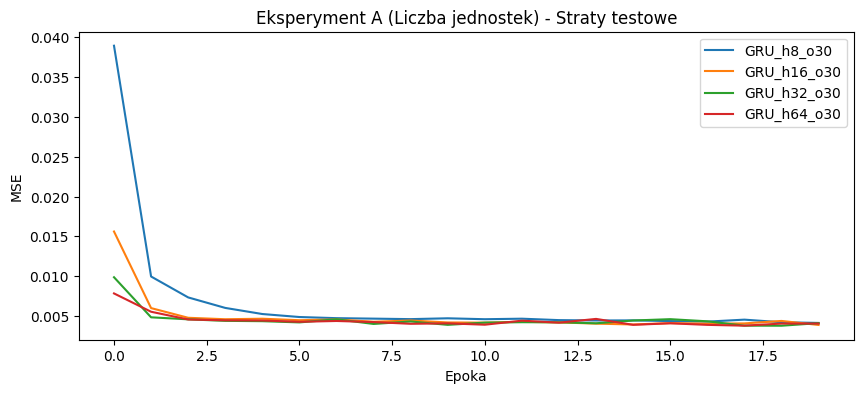

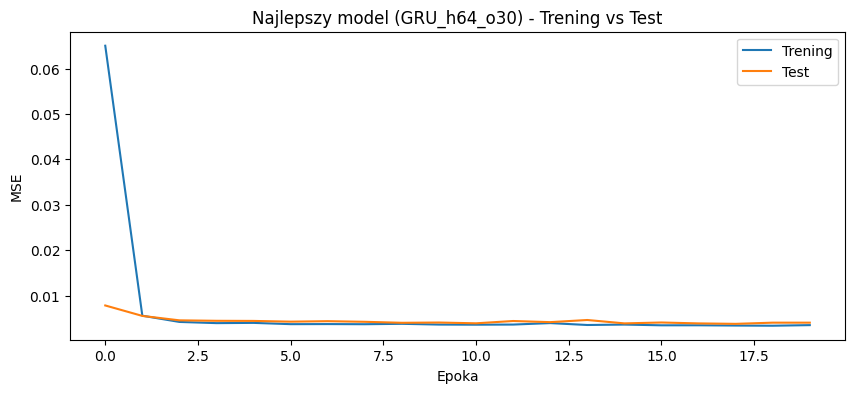

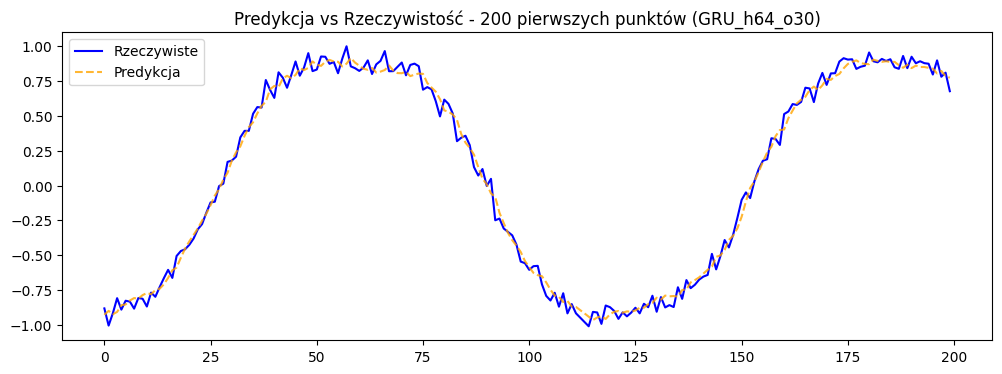

\nEksperyment B (Długość okna)
Konfiguracja       | Parametry  | Test MSE (średnia ± std)  | Czas (s)  
Heurystyka         | -          | 0.007220                  | -         
GRU_h32_o10        | 3393       | 0.004711 ± 0.000169 | 2.58
GRU_h32_o30        | 3393       | 0.004115 ± 0.000156 | 5.77
GRU_h32_o60        | 3393       | 0.003811 ± 0.000127 | 11.39
GRU_h32_o120       | 3393       | 0.003830 ± 0.000278 | 21.66


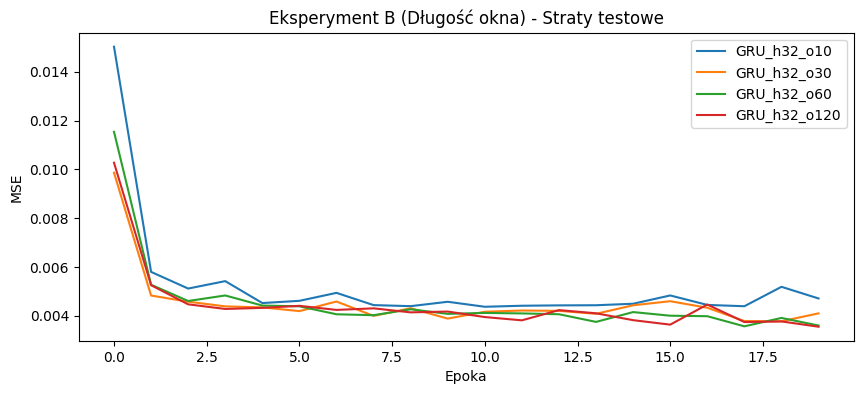

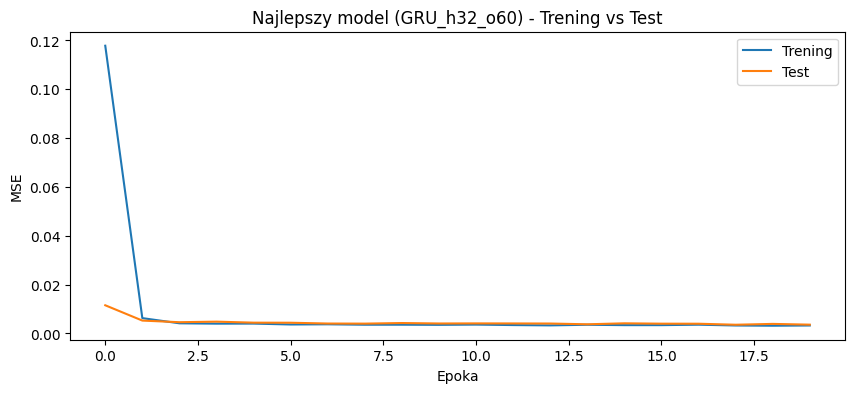

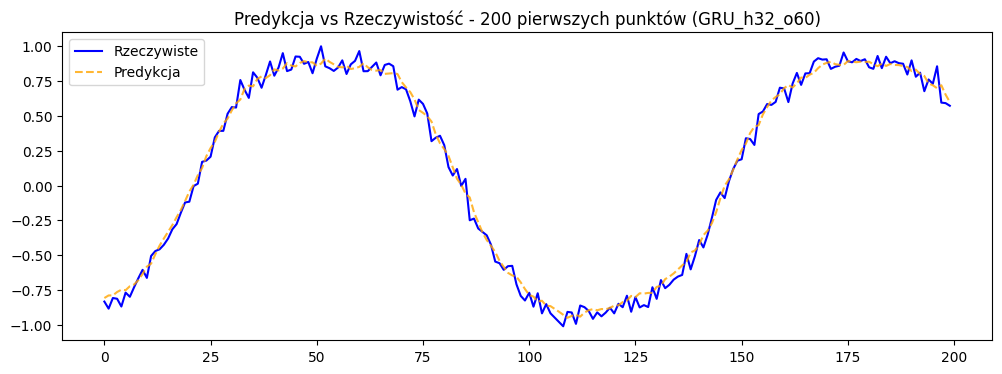

\nEksperyment C (Typ komórki, OKNO=10)
Konfiguracja       | Parametry  | Test MSE (średnia ± std)  | Czas (s)  
Heurystyka         | -          | 0.007175                  | -         
RNN_h32_o10        | 1153       | 0.004753 ± 0.000065 | 1.15
LSTM_h32_o10       | 4513       | 0.004490 ± 0.000078 | 1.93
GRU_h32_o10        | 3393       | 0.004711 ± 0.000169 | 2.26


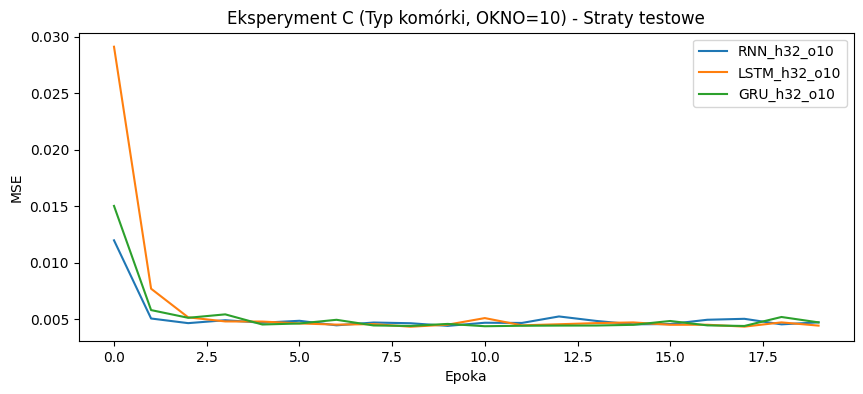

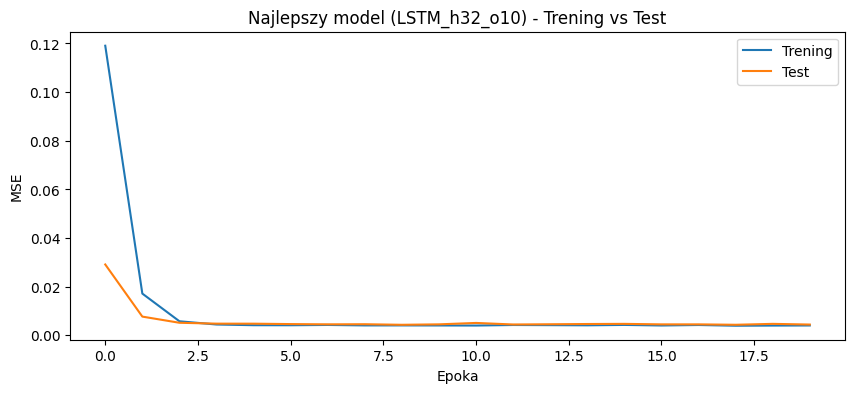

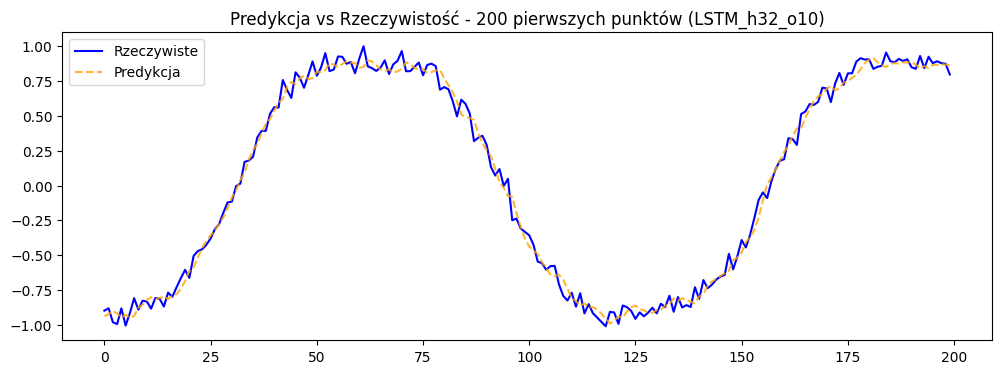

\nEksperyment C (Typ komórki, OKNO=120)
Konfiguracja       | Parametry  | Test MSE (średnia ± std)  | Czas (s)  
Heurystyka         | -          | 0.007243                  | -         
RNN_h32_o120       | 1153       | 0.004543 ± 0.000153 | 7.66
LSTM_h32_o120      | 4513       | 0.004174 ± 0.000111 | 10.29
GRU_h32_o120       | 3393       | 0.003830 ± 0.000278 | 21.07


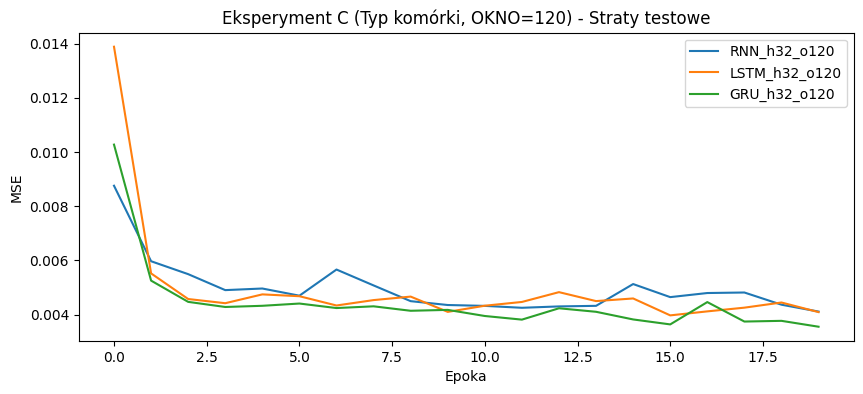

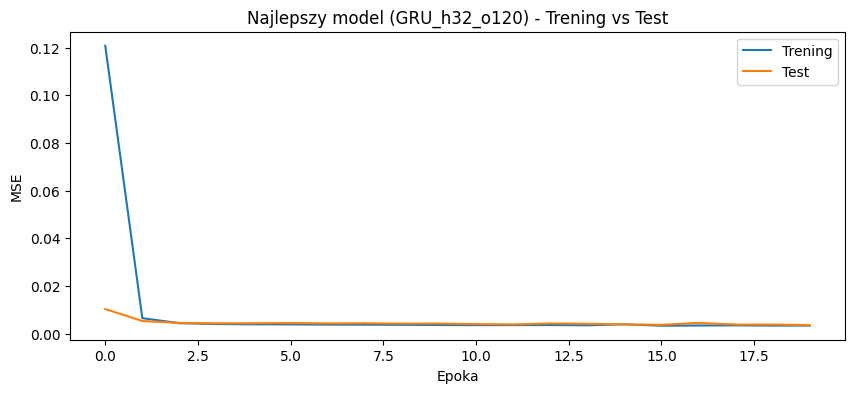

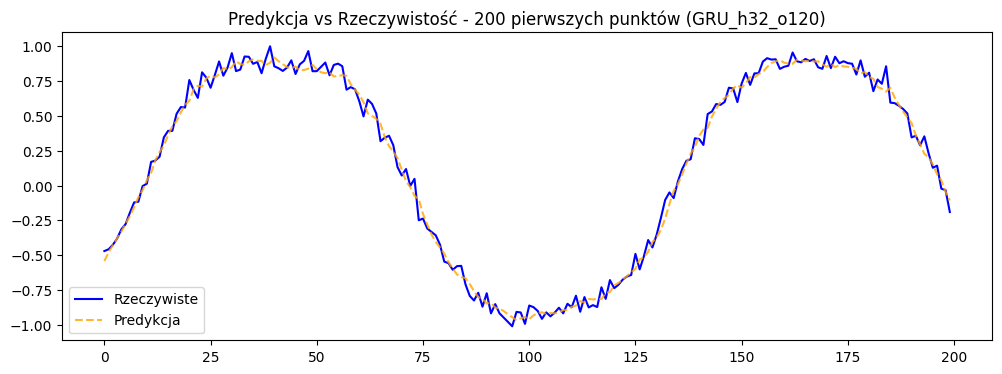

In [6]:
#eksperyment A
wyniki_A = []
for h in [8, 16, 32, 64]:
    res = uruchom_eksperyment(typ='GRU', hidden=h, okno=30)
    wyniki_A.append(res)
wyswietl_tabele_i_wykresy("Eksperyment A (Liczba jednostek)", wyniki_A, Xte_bazowe, Yte_bazowe)


#eksperyment B
wyniki_B = []
for o in [10, 30, 60, 120]:
    res = uruchom_eksperyment(typ='GRU', hidden=32, okno=o)
    wyniki_B.append(res)
wyswietl_tabele_i_wykresy("Eksperyment B (Długość okna)", wyniki_B, Xte_bazowe, Yte_bazowe)


#eksperyment C
for okno_skrajne in [10, 120]:
    wyniki_C = []
    _, _, Xte_C, Yte_C = przygotuj_dane(seria, okno=okno_skrajne)
    for typ_komorki in ['RNN', 'LSTM', 'GRU']:
        res = uruchom_eksperyment(typ=typ_komorki, hidden=32, okno=okno_skrajne)
        wyniki_C.append(res)
    wyswietl_tabele_i_wykresy(f"Eksperyment C (Typ komórki, OKNO={okno_skrajne})", wyniki_C, Xte_C, Yte_C)